In [1]:
import numpy as np
import pandas as pd

input_file = "kc_house_data.csv"
df = pd.read_csv(input_file)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long           21

In [2]:
def make_features(df):
    X = df.drop(["id", "price", "date"], axis=1).copy()   # id 는 집 번호라 필요 없는 특성으로 제거
    d = pd.to_datetime(df["date"].str[:8])                 # date 는 숫자로 변환해 사용
    X["sale_year"] = d.dt.year
    X["sale_month"] = d.dt.month
    X["sale_t"] = (d - d.min()).dt.days
    X["age"] = X["sale_year"] - X["yr_built"]
    X["renov"] = (X["yr_renovated"] > 0).astype(int)
    X["since_renov"] = np.where(X["yr_renovated"] > 0, X["sale_year"] - X["yr_renovated"], X["age"])
    X["rot1"] = X["lat"] + X["long"]
    X["rot2"] = X["lat"] - X["long"]
    for name, (la, lo) in {"seattle": (47.6062, -122.3321), "bellevue": (47.6101, -122.2015)}.items():
        X["dist_" + name] = np.sqrt((X["lat"] - la) ** 2 + ((X["long"] - lo) * 0.67) ** 2)
    for a in [15, 30, 60, 75]:
        r = np.deg2rad(a)
        X["rot%d" % a] = X["lat"] * np.cos(r) + X["long"] * np.sin(r)
    X["liv_ratio15"] = X["sqft_living"] / X["sqft_living15"]
    X["lot_ratio15"] = X["sqft_lot"] / X["sqft_lot15"]
    X["liv_per_lot"] = X["sqft_living"] / X["sqft_lot"]
    return X

housing_base = df.drop(["id", "price", "date"], axis=1)
housing_prepared = make_features(df)
housing_labels = df["price"].copy()
housing_prepared.shape

(21613, 35)

In [3]:
def display_scores(scores):
    print("Scores:", scores)
    print("Mean:", scores.mean())
    print("Standard deviation:", scores.std())

In [4]:
# 1) 모델 비교: 원본 특성 vs 내 특성, 여러 회귀 모델 (10-fold RMSE)
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

def rmse_cv(model, X):
    return np.sqrt(-cross_val_score(model, X, housing_labels, scoring="neg_mean_squared_error", cv=10, n_jobs=-1)).mean()

models = {
    "LinearRegression": LinearRegression(),
    "DecisionTree": DecisionTreeRegressor(random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGB": XGBRegressor(n_estimators=500, learning_rate=0.05, n_jobs=1),
    "LGBM": LGBMRegressor(n_estimators=500, learning_rate=0.05, verbose=-1, n_jobs=1),
}
for name, model in models.items():
    print(f"{name:18s} 원본 {rmse_cv(model, housing_base):10.0f}   내 특성 {rmse_cv(model, housing_prepared):10.0f}")

LinearRegression   원본     201997   내 특성     189218


DecisionTree       원본     178698   내 특성     173440


RandomForest       원본     128331   내 특성     122395


XGB                원본     121267   내 특성     113707


LGBM               원본     119700   내 특성     114888


In [5]:
# 2) 하이퍼파라미터 탐색: LGBM (Randomized Search, 5-fold)
from sklearn.model_selection import RandomizedSearchCV

param_distribs = {"num_leaves": [15, 31, 63], "learning_rate": [0.01, 0.03, 0.05],
                  "colsample_bytree": [0.4, 0.6, 0.8], "subsample": [0.7, 0.8, 1.0]}
rnd_search = RandomizedSearchCV(LGBMRegressor(n_estimators=1500, subsample_freq=1, verbose=-1, n_jobs=1),
                                param_distribs, n_iter=10, cv=5, scoring="neg_mean_squared_error",
                                random_state=42, n_jobs=-1)
rnd_search.fit(housing_prepared, housing_labels)
print(rnd_search.best_params_, np.sqrt(-rnd_search.best_score_))
for mean, params in zip(rnd_search.cv_results_["mean_test_score"], rnd_search.cv_results_["params"]):
    print(f"{np.sqrt(-mean):10.0f}", params)

{'subsample': 0.8, 'num_leaves': 15, 'learning_rate': 0.03, 'colsample_bytree': 0.4} 109799.27861336687
    112501 {'subsample': 0.7, 'num_leaves': 31, 'learning_rate': 0.01, 'colsample_bytree': 0.6}
    114005 {'subsample': 0.7, 'num_leaves': 15, 'learning_rate': 0.01, 'colsample_bytree': 0.4}
    110941 {'subsample': 0.8, 'num_leaves': 31, 'learning_rate': 0.05, 'colsample_bytree': 0.4}
    112677 {'subsample': 0.8, 'num_leaves': 31, 'learning_rate': 0.01, 'colsample_bytree': 0.6}
    110101 {'subsample': 0.7, 'num_leaves': 15, 'learning_rate': 0.05, 'colsample_bytree': 0.4}
    114304 {'subsample': 0.8, 'num_leaves': 15, 'learning_rate': 0.01, 'colsample_bytree': 0.6}
    109799 {'subsample': 0.8, 'num_leaves': 15, 'learning_rate': 0.03, 'colsample_bytree': 0.4}
    112921 {'subsample': 0.8, 'num_leaves': 63, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
    112508 {'subsample': 0.8, 'num_leaves': 31, 'learning_rate': 0.01, 'colsample_bytree': 0.4}
    110499 {'subsample': 0.7, 'n

In [6]:
# 3) 최종 모델: XGB·LGBM (원래 가격 / log 가격) 4개를 Stacking
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import StackingRegressor

def xgb():
    return XGBRegressor(n_estimators=3000, learning_rate=0.01, max_depth=6, subsample=0.8, colsample_bytree=0.6, n_jobs=1)

def lgbm():
    return LGBMRegressor(n_estimators=4000, learning_rate=0.01, num_leaves=31, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.6, verbose=-1, n_jobs=1)

def log_target(model):
    return TransformedTargetRegressor(model, func=np.log, inverse_func=np.exp)

final_reg = StackingRegressor(
    estimators=[("xgb", xgb()), ("xgb_log", log_target(xgb())), ("lgbm", lgbm()), ("lgbm_log", log_target(lgbm()))],
    final_estimator=LinearRegression(positive=True), cv=5)

In [7]:
final_scores = cross_val_score(final_reg, housing_prepared, housing_labels,
                               scoring="neg_mean_squared_error", cv=10, n_jobs=-1)
final_rmse_scores = np.sqrt(-final_scores)
display_scores(final_rmse_scores)

Scores: [ 98779.91447706 125402.76779507  92687.65352604 127182.0899933
  95331.69217802  97024.2315839  101742.42865076 101133.28860966
 102655.27942775 113685.71733223]
Mean: 105562.50635737958
Standard deviation: 11657.73966913522


In [8]:
np.mean(final_rmse_scores)

np.float64(105562.50635737958)

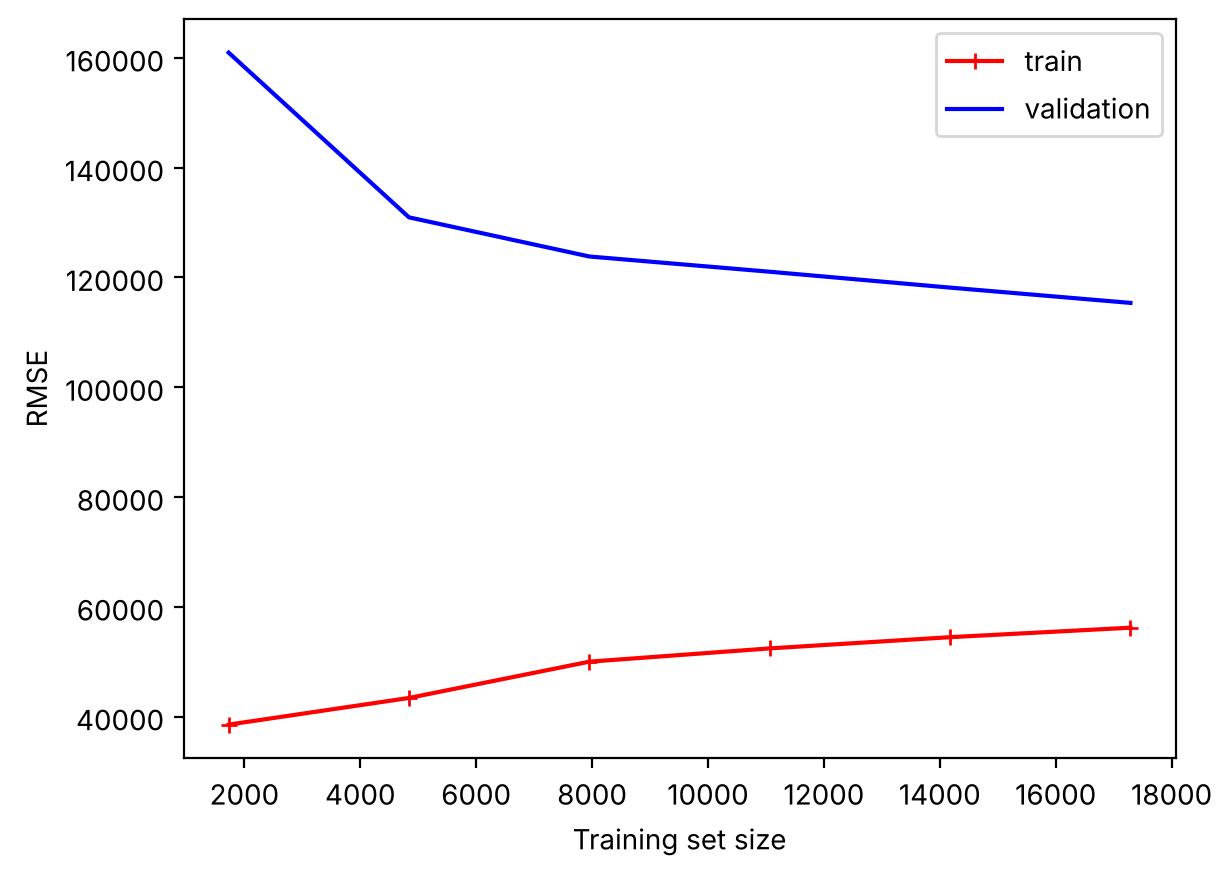

In [9]:
# 학습 곡선: 학습 데이터 양에 따른 학습/검증 RMSE
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(LGBMRegressor(n_estimators=1000, learning_rate=0.03, verbose=-1, n_jobs=1), housing_prepared, housing_labels, cv=5, scoring="neg_mean_squared_error",
                                         train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)
plt.plot(sizes, np.sqrt(-train_sc.mean(axis=1)), "r-+", label="train")
plt.plot(sizes, np.sqrt(-val_sc.mean(axis=1)), "b-", label="validation")
plt.xlabel("Training set size"); plt.ylabel("RMSE"); plt.legend(); plt.show()